In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("../data/simulation_results.csv")
df.head()

,sim,model_knowledge,w,perf,perf_stake,baseline_reward,avg_reward
0,0,0.0,0.00,0.248047,0.763672,4.408203,4.656250
1,0,0.0,0.01,-0.017578,-0.126953,4.408203,4.390625
2,0,0.0,0.02,0.009766,0.041016,4.408203,4.417969
3,0,0.0,0.03,0.138672,0.263672,4.408203,4.546875
4,0,0.0,0.04,0.048828,-0.341797,4.408203,4.457031


In [4]:
df_plot = (
    df.groupby(["model_knowledge", "w"], as_index=False)["perf_stake"].mean()
)
df_plot

,model_knowledge,w,perf_stake
0,0.0,0.00,0.488633
1,0.0,0.01,0.495742
2,0.0,0.02,0.455313
3,0.0,0.03,0.382148
4,0.0,0.04,0.375586
...,...,...,...
10196,1.0,0.96,1.502031
10197,1.0,0.97,1.615078
10198,1.0,0.98,1.427578
10199,1.0,0.99,1.613867


In [7]:
df_plot = (
    df.groupby(["model_knowledge", "w"], as_index=False)["perf_stake"]
      .mean()
      .assign(
          model_knowledge=lambda d: ((d["model_knowledge"] * 100 - 50) / 50).round(2),
          w=lambda d: d["w"].round(2)
      )
)
df_plot.head()

,model_knowledge,w,perf_stake
0,-1.0,0.00,0.488633
1,-1.0,0.01,0.495742
2,-1.0,0.02,0.455313
3,-1.0,0.03,0.382148
4,-1.0,0.04,0.375586


In [20]:
df_plot[df_plot["model_knowledge"] == 0.0]

,model_knowledge,w,perf_stake
5050,0.0,0.00,0.494219
5051,0.0,0.01,0.462773
5052,0.0,0.02,0.509453
5053,0.0,0.03,0.492109
5054,0.0,0.04,0.503594
...,...,...,...
5146,0.0,0.96,0.008711
5147,0.0,0.97,0.003672
5148,0.0,0.98,0.025430
5149,0.0,0.99,-0.024609


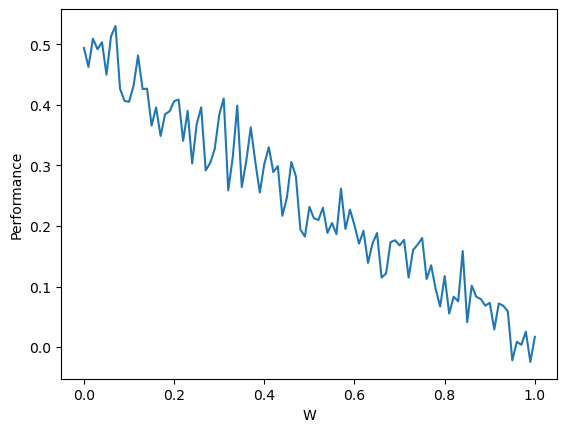

In [ ]:
sns.lineplot(
    data=df_plot[df_plot["model_knowledge"] == 0.0],
    x="w",
    y="perf_stake"
)

plt.title("Model knowledge at 0 (random)")
plt.xlabel("W")
plt.ylabel("Performance")
plt.show()


In [8]:
matrix = df_plot.pivot(index="model_knowledge", columns="w", values="perf_stake")
matrix.head()

w,0.00,0.01,0.02,0.03,0.04,0.05,0.06,0.07,0.08,0.09,...,0.91,0.92,0.93,0.94,0.95,0.96,0.97,0.98,0.99,1.00
model_knowledge,,,,,,,,,,,,,,,,,,,,,
-1.00,0.488633,0.495742,0.455313,0.382148,0.375586,0.399648,0.367500,0.446484,0.316797,0.203008,...,-1.499141,-1.590508,-1.533320,-1.489531,-1.485078,-1.497422,-1.508203,-1.477969,-1.490039,-1.414648
-0.98,0.523906,0.456641,0.436719,0.394492,0.444844,0.393281,0.359102,0.268633,0.288477,0.257422,...,-1.488672,-1.543320,-1.488516,-1.446445,-1.571641,-1.555937,-1.541602,-1.491445,-1.479531,-1.496563
-0.96,0.464844,0.466758,0.466289,0.411719,0.328633,0.410859,0.409531,0.252852,0.242461,0.275859,...,-1.457227,-1.473047,-1.566953,-1.465195,-1.555508,-1.483906,-1.506289,-1.490820,-1.482852,-1.456328
-0.94,0.527734,0.508359,0.488555,0.366484,0.459961,0.381563,0.350469,0.353086,0.284766,0.331016,...,-1.491719,-1.510078,-1.495391,-1.542812,-1.561289,-1.535977,-1.495859,-1.488711,-1.534453,-1.456445
-0.92,0.512227,0.437617,0.488984,0.463047,0.386836,0.367852,0.286758,0.357656,0.285117,0.308398,...,-1.507539,-1.521211,-1.550977,-1.506641,-1.513281,-1.512422,-1.551484,-1.473672,-1.544531,-1.468398


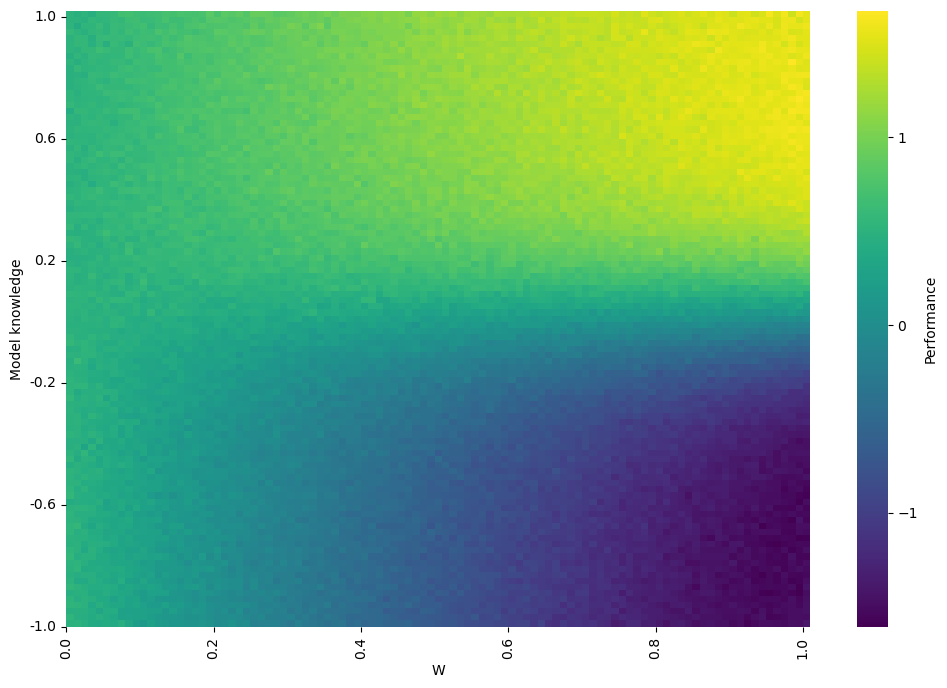

In [9]:
plt.figure(figsize=(12, 8))

sns.heatmap(matrix, cmap="viridis", annot=False, cbar_kws={"label": "Performance", "ticks": [-1., 0.0, 1.]})

# plt.contour(matrix.values, levels=[0], colors="black", linewidths=1)
# plt.axhline(y=50, color="red", linestyle="--", linewidth=2)

plt.gca().invert_yaxis()
plt.ylabel("Model knowledge")
plt.xlabel("W")

# Use the actual index and columns
plt.yticks(
    np.arange(0, len(matrix.index), 20),   # positions
    matrix.index[::20]                     # labels
)
plt.xticks(
    np.arange(0, len(matrix.columns), 20),  # positions
    matrix.columns[::20]                    # labels
)

plt.show()


## Mapping real data on the matrix

get value from behaviour data

In [25]:
df_behaviour = pd.read_csv("../data/data_participants.csv")
df_w_language = pd.read_csv("../data/data_participants_w_language.csv")
df_w_observation = pd.read_csv("../data/data_participants_w_observation.csv")

df_behaviour["gen"] = df_behaviour["gen"] + 1
df_behaviour["pl2_understanding"] = (df_behaviour["pl2_understanding"] * 50 + 50) / 100

df_language = df_behaviour.query('cond == "ADV"')
language_value = {
    "gen": range(1, 11),
    "perf": df_language.groupby("gen")["score_corrected"].mean().round(2),
    "model_knowledge": df_language.groupby("gen")["pl2_understanding"].mean().round(2),
    "w": df_w_language.groupby("generation")["w"].mean().round(2)
}
df_language = pd.DataFrame(language_value)

df_observation = df_behaviour.query('cond == "OBS"')
observation_value = {
    "gen": range(1, 11),
    "perf": df_observation.groupby("gen")["score_corrected"].mean().round(2),
    "model_knowledge": df_observation.groupby("gen")["pl2_understanding"].mean().round(2),
    "w": df_w_observation.groupby("generation")["w"].mean().round(2)
}
df_observation = pd.DataFrame(observation_value)

value from the sim

In [26]:
df_sim = pd.read_csv("../data/simulation_language_results.csv")
df_sim = (
    df_sim.groupby(["model_knowledge", "w"], as_index=False)["perf_stake"].mean().round(2)
)
df_sim = df_sim.rename(columns={"perf_stake": "perf_sim"})
df_sim

,model_knowledge,w,perf_sim
0,0.0,0.00,0.50
1,0.0,0.01,0.48
2,0.0,0.02,0.43
3,0.0,0.03,0.37
4,0.0,0.04,0.44
...,...,...,...
10196,1.0,0.96,1.50
10197,1.0,0.97,1.56
10198,1.0,0.98,1.54
10199,1.0,0.99,1.54


In [27]:
df_language = df_language.merge(
    df_sim[["model_knowledge", "w", "perf_sim"]],
    on=["model_knowledge", "w"],
    how="left"
)
df_language

,gen,perf,model_knowledge,w,perf_sim
0,1,0.19,0.53,0.51,0.46
1,2,0.25,0.52,0.53,0.38
2,3,0.31,0.53,0.51,0.46
3,4,0.43,0.52,0.51,0.40
4,5,0.45,0.55,0.52,0.46
5,6,0.43,0.57,0.53,0.67
6,7,0.45,0.60,0.53,0.77
7,8,0.70,0.65,0.60,0.96
8,9,1.15,0.74,0.66,1.15
9,10,1.06,0.75,0.69,1.23


In [28]:
df_observation = df_observation.merge(
    df_sim[["model_knowledge", "w", "perf_sim"]],
    on=["model_knowledge", "w"],
    how="left"
)
df_observation

,gen,perf,model_knowledge,w,perf_sim
0,1,0.30,0.51,0.49,0.36
1,2,0.20,0.52,0.49,0.40
2,3,0.28,0.51,0.49,0.36
3,4,0.33,0.53,0.51,0.46
4,5,0.05,0.51,0.49,0.36
5,6,0.18,0.52,0.51,0.40
6,7,0.31,0.52,0.49,0.40
7,8,0.21,0.52,0.51,0.40
8,9,0.30,0.53,0.53,0.49
9,10,0.26,0.52,0.49,0.40


merger & save data for R

In [29]:
df_language["condition"] = "language"
df_observation["condition"] = "observation"
df = pd.concat([df_language, df_observation], ignore_index=True)
df.to_csv("../data/data_matrix_behaviour_comparaison.csv", index=False)

## plot

In [30]:
df

,gen,perf,model_knowledge,w,perf_sim,condition
0,1,0.19,0.53,0.51,0.46,language
1,2,0.25,0.52,0.53,0.38,language
2,3,0.31,0.53,0.51,0.46,language
3,4,0.43,0.52,0.51,0.40,language
4,5,0.45,0.55,0.52,0.46,language
5,6,0.43,0.57,0.53,0.67,language
6,7,0.45,0.60,0.53,0.77,language
7,8,0.70,0.65,0.60,0.96,language
8,9,1.15,0.74,0.66,1.15,language
9,10,1.06,0.75,0.69,1.23,language


Performance

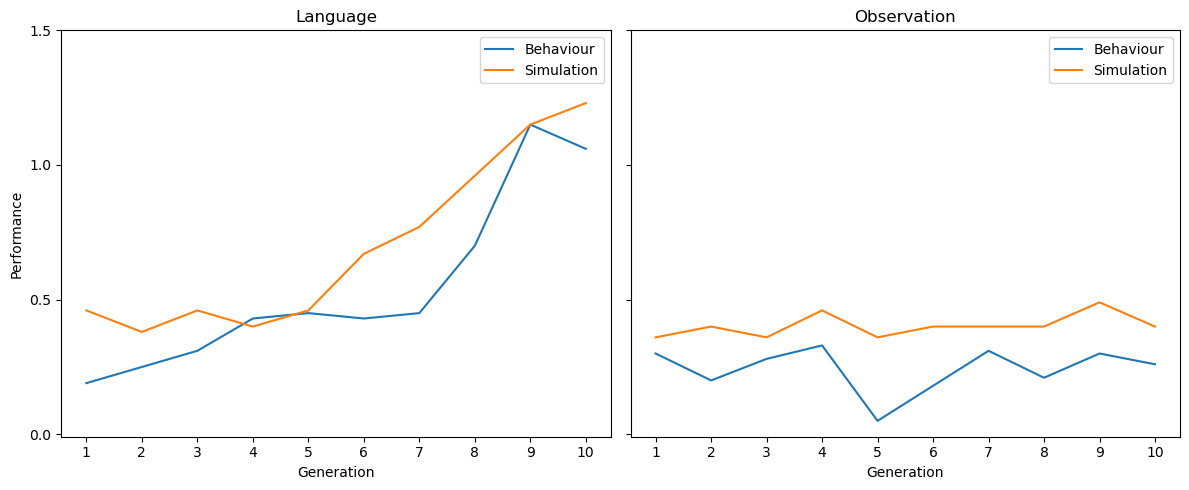

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Language
ax = axes[0]
df_plot_language = df.query('condition == "language"')

ax.plot("gen", "perf", data=df_plot_language, label="Behaviour")
ax.plot("gen", "perf_sim", data=df_plot_language, label="Simulation")

ax.set_title("Language")
ax.set_xlabel("Generation")
ax.set_ylabel("Performance")

ax.set_xticks(range(1, 11, 1))
ax.set_yticks([0, 0.5, 1.0, 1.5])
ax.legend()

# Observation
ax = axes[1]
df_plot_observation = df.query('condition == "observation"')

ax.plot("gen", "perf", data=df_plot_observation, label="Behaviour")
ax.plot("gen", "perf_sim", data=df_plot_observation, label="Simulation")

ax.set_title("Observation")
ax.set_xlabel("Generation")

ax.set_xticks(range(1, 11, 1))
ax.set_yticks([0, 0.5, 1.0, 1.5])
ax.legend()

plt.tight_layout()
plt.show()